# First image through an Endpoint

Run this notebook on your **laptop**. It calls Sana, an open text-to-image model, running on a GPU as a Nebius Serverless AI Endpoint.

You'll generate an image, then run four small experiments that show what stays the same between generations and what doesn't. You're done when the images and your notes are on your laptop and the Endpoint is no longer `RUNNING`.

> The Endpoint bills from the moment it starts until you stop it, idle or not. Create it right before you run this notebook, and finish with the last cell.

Guide: [02-first-generation.md](../02-first-generation.md). Setup (account, credits, `uv`): the **Setup** section of the [module README](../README.md).

## 1. Connect to your Endpoint

Create the Endpoint in the web console first (see the guide). Then run this cell. It reads `code/.env` and the environment, and asks only for what is still missing: the HTTPS URL and the token.

The answers are saved to `code/.env` (readable only by you, and ignored by Git). To be asked again, delete those lines and restart the kernel.

The token is typed with `getpass`, so it is never echoed. Treat it like a password: don't paste it into a cell, a screenshot or a chat.

In [1]:
import sys
import time
from pathlib import Path

from IPython.display import Image, display

MODULE = "01-consistent-media-generation-on-serverless-gpus"
candidates = [Path.cwd(), Path.cwd() / "code", Path.cwd() / MODULE / "code"]
found = [p for p in candidates if (p / "common.py").is_file()]
assert found, "Open this notebook from the repository (its code/ folder)"
CODE = found[0].resolve()
sys.path.insert(0, str(CODE))

from common import asset_record, output_dir, setup_endpoint, wait_ready
from image import ImageGenerator, image_comparison, request_id

BASE_URL, TOKEN = setup_endpoint()


Endpoint configured (***npDL)


## 2. Wait until it's ready

`RUNNING` in the console means the container started, not that the model is loaded. Until the server has downloaded and loaded the weights, calls return `502`.

This cell polls `/v1/models` every 2 seconds until the model answers. It gives up after 10 minutes; re-running it is safe.

In [2]:
start = time.perf_counter()
models = wait_ready(BASE_URL, TOKEN, deadline_s=600)
print("Served models:", [m.get("id") for m in models["data"]])
print(f"Ready after {time.perf_counter() - start:.0f} s of waiting")

Served models: ['Efficient-Large-Model/Sana_1600M_1024px_diffusers']
Ready after 0 s of waiting


## 3. Generate an image

One POST to `/v1/images/generations`. The body is the model, the prompt, and the settings. The token goes in the `Authorization` header. The response is a PNG, base64-encoded in `data[0].b64_json`.

Change the prompt if you like. Keep it free of real people, brands and known characters. Each side of `size` must be a multiple of 32.

If `REQUESTS_CA_BUNDLE` is set, `requests` uses that file instead of the public CAs. This call passes the public bundle.


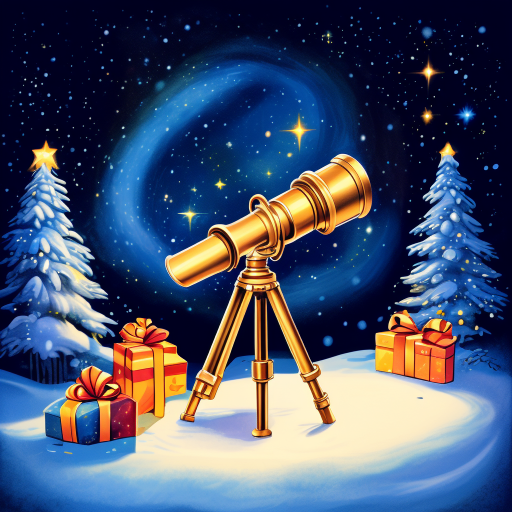

In [3]:
import base64

import certifi
import requests

prompt = (
    "A storybook illustration of a brass telescope glowing on snow under a starry night sky, "
    "a small decorated tree and wrapped presents, warm colors, no people, no text"
)

request_data = {
    "model": "Efficient-Large-Model/Sana_1600M_1024px_diffusers",
    "prompt": prompt,
    "size": "512x512",
    "seed": 7,
    "response_format": "b64_json",
}

response = requests.post(
    f"{BASE_URL}/v1/images/generations",
    headers={"Authorization": f"Bearer {TOKEN}"},
    json=request_data,
    timeout=300,
    verify=certifi.where(),
)
response.raise_for_status()
png = base64.b64decode(response.json()["data"][0]["b64_json"])
display(Image(data=png))


`ImageGenerator` does the same work as the cell above: it posts that body, saves the PNG, and returns the path. The experiments below use it, so each call is one line.


Generated in 1.2 s
Saved /Users/mnrozhkov/dev/course_media_agent/production-ai-agents-for-media-generation/01-consistent-media-generation-on-serverless-gpus/code/runs/first-image.png


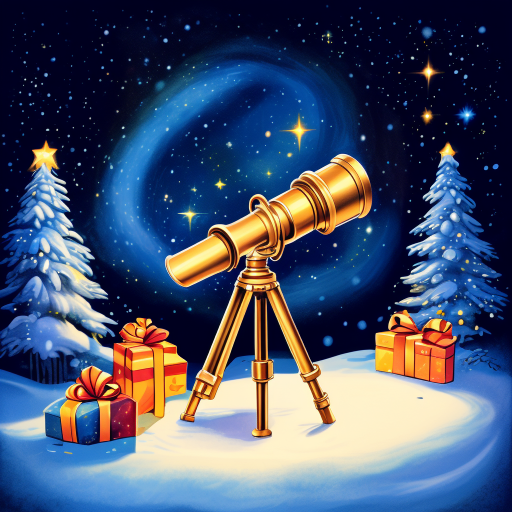

In [4]:
prompt = (
    "A storybook illustration of a brass telescope glowing on snow under a starry night sky, "
    "a small decorated tree and wrapped presents, warm colors, no people, no text"
)

generator = ImageGenerator(BASE_URL, TOKEN)
out = generator.generate_image(prompt)
print("Saved", out)
display(Image(filename=str(out)))

## 4. Same settings, same image

Generate the same image three times with exactly the same settings. Then compare the hashes. With the same prompt, seed and settings on the same Endpoint, are the three images byte-identical?


Generated in 1.2 s
Generated in 1.2 s
Generated in 1.2 s
Hashes: ['6dd0a6ff2029', '6dd0a6ff2029', '6dd0a6ff2029'] | identical: True


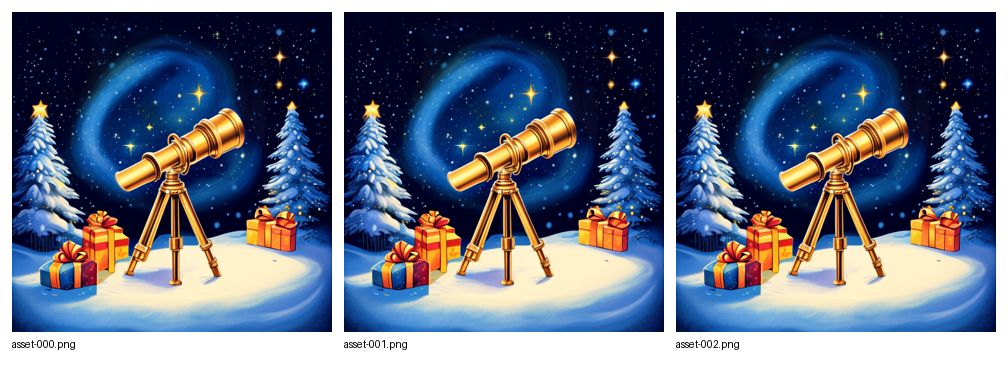

In [9]:
folder = output_dir(None)
paths = [
    generator.generate_image(prompt, out=folder / f"asset-{index:03d}.png", seed=7)
    for index in range(3)
]
hashes = [asset_record(path)["sha256"] for path in paths]
print("Hashes:", [h[:12] for h in hashes], "| identical:", len(set(hashes)) == 1)
display(Image(data=image_comparison(paths)))


## 5. Leave out the seed

Same prompt and settings, but no seed: the server picks a random one for every call. Two calls, two different images. A seed you didn't record is a setting you can't repeat.

Generated in 1.2 s
Generated in 1.2 s


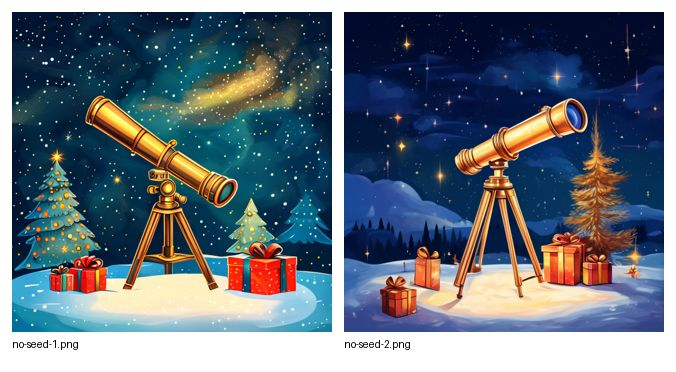

Identical: False


In [6]:
no_seed = []
for i in (1, 2):
    path = generator.generate_image(prompt, out=folder / f"no-seed-{i}.png", seed=None)
    no_seed.append(asset_record(path))

display(Image(data=image_comparison([folder / a["file"] for a in no_seed])))

print("Identical:", no_seed[0]["sha256"] == no_seed[1]["sha256"])

## 6. The seed is a setting

Now a character: the same description goes into every prompt below. First, the same scene with seed 7 and seed 8. The seed changes the picture as much as any other setting does.

Before you go on, look at the seed-7 image: does it show the scarf and the spectacles? If Sana skips a trait even here, don't count it in step 7.

Generated in 1.2 s
Generated in 1.2 s


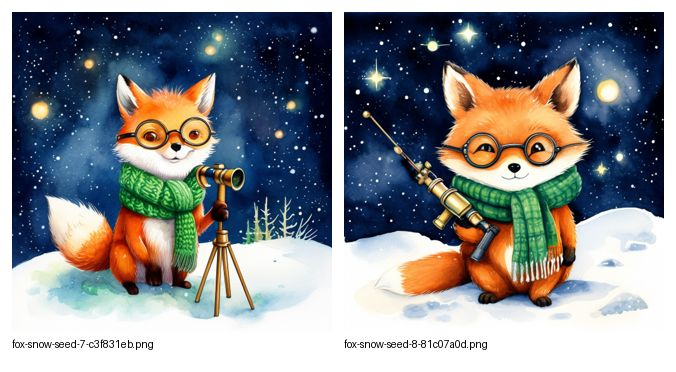

Generated in 1.2 s
Generated in 1.2 s


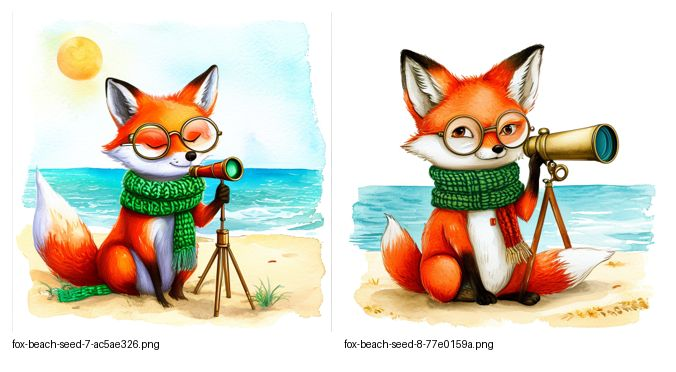

In [ ]:
CHARACTER = (
    "a small red fox with a white chest, round brass spectacles and a green knitted scarf, "
    "holding a brass telescope; watercolor storybook illustration, soft painterly texture, no text"
)
scenes = {
    "snow": f"{CHARACTER}. The fox sits in the snow under a starry night sky.",
    "beach": f"{CHARACTER}. The fox sits on a sunny beach by the sea.",
}


def fox(scene, seed):
    """Generate once per exact request; re-running the cell reuses the file only if nothing changed."""
    request = dict(model=generator.model, prompt=scenes[scene], seed=seed)
    path = folder / f"fox-{scene}-seed-{seed}-{request_id(**request)}.png"
    if not path.exists():
        generator.generate_image(request["prompt"], out=path, seed=seed)

    return path


display(Image(data=image_comparison([fox("snow", seed) for seed in (7, 8)])))


## 7. Same character, new scene

Same character description, same seed, a different scene. Compare the two foxes: which traits survived, and what changed? Write it down in the next cell, with three short answers.

A prompt describes a character; it doesn't hold one fixed. Keeping a character across scenes takes more than a prompt and a seed.

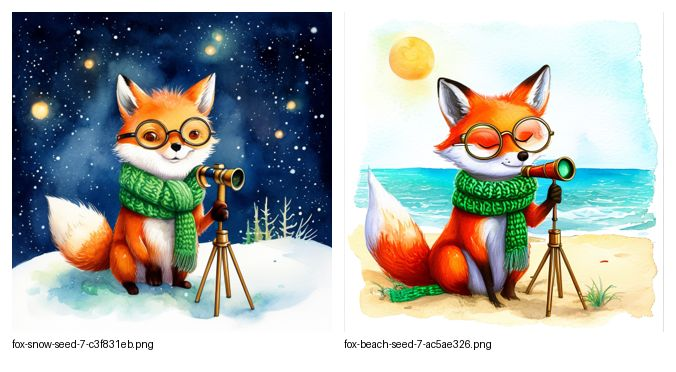

In [11]:
identity_row = [fox("snow", 7), fox("beach", 7)]
display(Image(data=image_comparison(identity_row)))


### Your notes

Double-click this cell and answer in place, one line each.

1. **Same character, new scene:** which traits survived, which changed?
   - *your answer*
2. **What must stay fixed** to get the same image again?
   - *your answer*
3. **Why didn't the seed** keep the fox the same?
   - *your answer*
4. **What would you try** for a product that needs the same character in every scene?
   - *your answer*


## 8. Stop the Endpoint

Do it now: open the Endpoint in the [web console](https://console.nebius.com/), click **Stop** (or **Delete**), and check that its status is `STOPPED`.

- **Stop** keeps the Endpoint and its URL; start it again later. Nothing bills for compute while it's stopped.
- **Delete** removes it. A new Endpoint gets a new URL and token. Delete `BASE_URL` and `TOKEN` from `code/.env`, restart the kernel, and run step 1 again.

You're done when:

- [ ] `runs/first-image.png` shows your image.
- [ ] Your run folder has the four `row-*.png` strips.
- [ ] You've answered the four questions in *Your notes*.
- [ ] The Endpoint is `STOPPED` or deleted.